
# AURORA cfDNA Regional Fragmentation Analysis  
## Step 4: Biological interpretation of tumor-fraction-associated regional bins

This notebook builds on Step 3.

### Main purpose

Step 4 interprets the **FDR-significant tumor-fraction-associated regional bins**, with special focus on the **sample-centered significant bins**.

### Why focus on sample-centered bins?

Raw regional bins showed a broad genome-wide tumor-fraction effect.  
Sample-centered bins remove each sample's genome-wide median regional short/long ratio and therefore highlight **regional redistribution** beyond the global sample-wide fragmentation shift.

### Primary Step 4 result set

```text
FDR-significant sample-centered tumor-fraction-associated bins
```

From Step 3, this set was:

```text
339 bins
```

### Step 4 goals

1. Separate raw vs sample-centered tumor-fraction significant bins  
2. Prioritize sample-centered significant bins  
3. Separate positive vs negative tumor-fraction coefficients  
4. Summarize by chromosome arm and cytoband  
5. Compare Step 3 significant bins with Step 2 significant chromosome arms  
6. Create BED files for downstream annotation/enrichment  
7. Generate cleaner PPT-ready plots    

In [13]:

# ============================================================
# STEP 1: Setup paths, parameters, imports, and helper functions
# ============================================================

from pathlib import Path
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

print("Step 4 notebook started:", time.ctime())

# -------------------------
# Project paths
# -------------------------

OUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/Result"
)

REGIONAL_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
)

STEP1_TABLE_DIR = OUT_DIR / "Step1_QC_tables"
STEP2_TABLE_DIR = OUT_DIR / "Step2_PCA_arm_chrom_models_tables"
STEP3_TABLE_DIR = OUT_DIR / "Step3_bin_level_screen_tables"

STEP4_TABLE_DIR = OUT_DIR / "Step4_biological_interpretation_tables"
STEP4_PLOT_DIR = OUT_DIR / "Step4_biological_interpretation_plots"
STEP4_BED_DIR = OUT_DIR / "Step4_biological_interpretation_BED"

for d in [STEP4_TABLE_DIR, STEP4_PLOT_DIR, STEP4_BED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------
# Required input files
# -------------------------

ANNO_FILE = STEP1_TABLE_DIR / "01_analysis_ready_sample_annotation.csv"
BIN_ANNOT_FILE = STEP1_TABLE_DIR / "01_bin_annotation_with_cytoband_chrom_arm.csv"

STEP2_ARM_MODEL_FILE = STEP2_TABLE_DIR / "02_chromosome_arm_level_clustered_model_results.csv"

STEP3_SIG_TFX_FILE = STEP3_TABLE_DIR / "03_significant_bins_tumor_fraction_FDR05_robust_screen.csv"
STEP3_ALL_RESULTS_FILE = STEP3_TABLE_DIR / "03_all_primary_model_results_robust_selected_bins.csv"
STEP3_GEE_FILE = STEP3_TABLE_DIR / "03_GEE_sensitivity_results_robust_screen.csv"

required_files = [
    ANNO_FILE,
    BIN_ANNOT_FILE,
    STEP2_ARM_MODEL_FILE,
    STEP3_SIG_TFX_FILE,
    STEP3_ALL_RESULTS_FILE,
]

for p in required_files:
    if not p.exists():
        raise FileNotFoundError(f"Missing required file: {p}")
    print("Found:", p)

if STEP3_GEE_FILE.exists():
    print("Found optional GEE sensitivity file:", STEP3_GEE_FILE)
else:
    print("Optional GEE sensitivity file not found:", STEP3_GEE_FILE)

# -------------------------
# gene annotation
# -------------------------
GTF_FILE = Path("/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf")

# -------------------------
# Parameters
# -------------------------

TFX_COL = "Tumor_Fraction_percent_from_CNV_annotation"

TREATMENT_ORDER = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment",
]

FDR_ALPHA = 0.05

STEP2_ARM_FDR_ALPHA = 0.05

TOP_N_BINS_FOR_HEATMAP = 100
TOP_N_POSITIVE_BINS_FOR_HEATMAP = 50
TOP_N_NEGATIVE_BINS_FOR_HEATMAP = 50

TOP_N_CYTOBANDS_PLOT = 25
TOP_N_ARMS_PLOT = 25

NEAREST_GENE_WINDOW_BP = 1_000_000

# Step 2 sample-centered significant arms from prior analysis.
# The notebook will also compute these directly from the Step 2 arm model file.
EXPECTED_STEP2_SAMPLE_CENTERED_SIG_ARMS = [
    "chr3q", "chr5p", "chr8q", "chr12q", "chr20q",
    "chr4p", "chr11p", "chr11q", "chr17p", "chr18q",
]

print("\nStep 4 output table directory:", STEP4_TABLE_DIR)
print("Step 4 output plot directory:", STEP4_PLOT_DIR)
print("Step 4 BED directory:", STEP4_BED_DIR)


# -------------------------
# Helper functions
# -------------------------

def clean_barcode(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip()


def chrom_sort_key(chrom):
    chrom = str(chrom).replace("chr", "")
    if chrom.endswith("p") or chrom.endswith("q"):
        chrom = chrom[:-1]
    if chrom.isdigit():
        return int(chrom)
    if chrom == "X":
        return 23
    if chrom == "Y":
        return 24
    if chrom in ["M", "MT"]:
        return 25
    return 999


def arm_sort_key(x):
    x = str(x)
    if x.endswith("p") or x.endswith("q"):
        return (chrom_sort_key(x[:-1]), x[-1])
    return (chrom_sort_key(x), "")


def safe_neglog10(x):
    x = pd.to_numeric(x, errors="coerce")
    return -np.log10(np.clip(x, 1e-300, 1.0))


def coefficient_direction(coef):
    if pd.isna(coef):
        return "missing"
    if coef > 0:
        return "positive"
    if coef < 0:
        return "negative"
    return "zero"


def write_bed_like(df, path, name_prefix):
    """
    Write a BED-like file with extra columns.
    BED required columns:
      chrom, start, end, name, score, strand
    Extra columns:
      bin, coefficient, p, q, direction, chrom_arm, cytoband
    """
    out = df.copy()
    out["chrom"] = out["chrom"].astype(str)
    out["start"] = pd.to_numeric(out["start"], errors="coerce").astype(int)
    out["end"] = pd.to_numeric(out["end"], errors="coerce").astype(int)

    out["name"] = [
        f"{name_prefix}_{i+1}_{b}"
        for i, b in enumerate(out["bin"].astype(str).tolist())
    ]

    # BED score must be 0-1000. Use capped -log10(q) scaled.
    if "q_tumor_fraction_percent" in out.columns:
        score = safe_neglog10(out["q_tumor_fraction_percent"]) * 100
        out["score"] = np.clip(score, 0, 1000).fillna(0).astype(int)
    else:
        out["score"] = 0

    out["strand"] = "."

    bed_cols = [
        "chrom", "start", "end", "name", "score", "strand",
        "bin", "coef_tumor_fraction_percent", "p_tumor_fraction_percent",
        "q_tumor_fraction_percent", "tfx_direction", "chrom_arm", "cytoband"
    ]

    bed_cols = [c for c in bed_cols if c in out.columns]

    out[bed_cols].to_csv(path, sep="\t", index=False, header=False)
    print("Saved BED-like file:", path, "rows:", out.shape[0])


def plot_horizontal_bar(df, label_col, value_col, path, title, xlabel, top_n=25):
    tmp = df.copy()
    tmp = tmp.sort_values(value_col, ascending=False).head(top_n)
    tmp = tmp.iloc[::-1].copy()

    fig, ax = plt.subplots(figsize=(8, max(4, 0.32 * tmp.shape[0])))
    ax.barh(tmp[label_col].astype(str), tmp[value_col])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def plot_direction_stacked_bar(summary_df, x_col, path, title):
    """
    Stacked horizontal bar for positive vs negative counts.
    """
    pivot = (
        summary_df
        .pivot_table(index=x_col, columns="tfx_direction", values="n_bins", aggfunc="sum", fill_value=0)
        .reset_index()
    )

    for col in ["positive", "negative"]:
        if col not in pivot.columns:
            pivot[col] = 0

    pivot["total"] = pivot["positive"] + pivot["negative"]
    pivot = pivot.sort_values("total", ascending=False).head(TOP_N_ARMS_PLOT)
    pivot = pivot.iloc[::-1].copy()

    fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * pivot.shape[0])))

    y = np.arange(pivot.shape[0])
    ax.barh(y, pivot["positive"], label="Positive TFx coefficient")
    ax.barh(y, -pivot["negative"], label="Negative TFx coefficient")

    ax.axvline(0, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(pivot[x_col].astype(str))
    ax.set_xlabel("Number of significant bins")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def parse_gtf_attributes(attr):
    """
    Parse GTF attributes into a dict.
    """
    d = {}
    if pd.isna(attr):
        return d
    parts = [x.strip() for x in str(attr).split(";") if x.strip()]
    for p in parts:
        if " " in p:
            key, val = p.split(" ", 1)
            d[key] = val.replace('"', '').strip()
    return d


def load_gene_gtf(gtf_path):
    """
    Load gene-level intervals from a GTF file.
    """
    cols = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    genes = pd.read_csv(
        gtf_path,
        sep="\t",
        comment="#",
        names=cols,
        low_memory=False,
    )

    genes = genes[genes["feature"].eq("gene")].copy()
    genes["start"] = pd.to_numeric(genes["start"], errors="coerce") - 1
    genes["end"] = pd.to_numeric(genes["end"], errors="coerce")

    attrs = genes["attribute"].apply(parse_gtf_attributes)
    genes["gene_name"] = attrs.apply(lambda d: d.get("gene_name", d.get("gene_id", "")))
    genes["gene_id"] = attrs.apply(lambda d: d.get("gene_id", ""))
    genes["gene_type"] = attrs.apply(lambda d: d.get("gene_type", d.get("gene_biotype", "")))

    genes = genes[["chrom", "start", "end", "strand", "gene_id", "gene_name", "gene_type"]].copy()
    genes = genes.dropna(subset=["chrom", "start", "end"])
    genes["start"] = genes["start"].astype(int)
    genes["end"] = genes["end"].astype(int)

    return genes


def annotate_nearest_gene(bins_df, genes_df, window_bp=1_000_000):
    """
    Simple nearest-gene annotation for a small bin set.
    For each bin, find overlapping genes and nearest gene within window.
    """
    annotated_rows = []

    genes_by_chrom = {
        chrom: sub.sort_values("start").copy()
        for chrom, sub in genes_df.groupby("chrom")
    }

    for _, row in bins_df.iterrows():
        chrom = row["chrom"]
        start = int(row["start"])
        end = int(row["end"])
        mid = int((start + end) / 2)

        sub = genes_by_chrom.get(chrom, pd.DataFrame())

        out = row.to_dict()
        out["overlapping_gene_names"] = ""
        out["nearest_gene_name"] = ""
        out["nearest_gene_distance_bp"] = np.nan
        out["nearest_gene_type"] = ""

        if not sub.empty:
            overlap = sub[(sub["start"] <= end) & (sub["end"] >= start)].copy()
            if overlap.shape[0] > 0:
                out["overlapping_gene_names"] = ";".join(sorted(overlap["gene_name"].dropna().unique()))

            candidate = sub[
                (sub["end"] >= mid - window_bp) &
                (sub["start"] <= mid + window_bp)
            ].copy()

            if candidate.shape[0] > 0:
                candidate["distance_bp"] = np.where(
                    (candidate["start"] <= mid) & (candidate["end"] >= mid),
                    0,
                    np.minimum(
                        np.abs(candidate["start"] - mid),
                        np.abs(candidate["end"] - mid)
                    )
                )
                best = candidate.sort_values("distance_bp").iloc[0]
                out["nearest_gene_name"] = best["gene_name"]
                out["nearest_gene_distance_bp"] = int(best["distance_bp"])
                out["nearest_gene_type"] = best["gene_type"]

        annotated_rows.append(out)

    return pd.DataFrame(annotated_rows)


Step 4 notebook started: Mon Jun 15 09:54:11 2026
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_analysis_ready_sample_annotation.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_bin_annotation_with_cytoband_chrom_arm.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step2_PCA_arm_chrom_models_tables/02_chromosome_arm_level_clustered_model_results.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step3_bin_level_screen_tables/03_significant_bins_tumor_fraction_FDR05_robust_screen.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step3_bin_level_screen_tables/03_all_primary_model_results_robust_select

In [14]:

# ============================================================
# STEP 2: Load Step 3 significant bins and Step 2 arm-level model results
# ============================================================

analysis_ready = pd.read_csv(ANNO_FILE)
bin_annot = pd.read_csv(BIN_ANNOT_FILE)
step2_arm = pd.read_csv(STEP2_ARM_MODEL_FILE)
sig_tfx = pd.read_csv(STEP3_SIG_TFX_FILE)
all_step3 = pd.read_csv(STEP3_ALL_RESULTS_FILE)

if STEP3_GEE_FILE.exists():
    gee = pd.read_csv(STEP3_GEE_FILE)
else:
    gee = pd.DataFrame()

analysis_ready["Barcode"] = analysis_ready["Barcode"].apply(clean_barcode)
analysis_ready["Patient_Identifier"] = analysis_ready["Patient_Identifier"].apply(clean_barcode)
analysis_ready[TFX_COL] = pd.to_numeric(analysis_ready[TFX_COL], errors="coerce")
analysis_ready["Treatment_Context_3group"] = pd.Categorical(
    analysis_ready["Treatment_Context_3group"],
    categories=TREATMENT_ORDER,
    ordered=True,
)

# Add a clean direction column.
sig_tfx["tfx_direction"] = sig_tfx["coef_tumor_fraction_percent"].apply(coefficient_direction)
all_step3["tfx_direction"] = all_step3["coef_tumor_fraction_percent"].apply(coefficient_direction)

print("Analysis-ready samples:", analysis_ready.shape[0])
print("Analysis-ready patients:", analysis_ready["Patient_Identifier"].nunique())
print("\nTreatment-context counts:")
display(analysis_ready["Treatment_Context_3group"].value_counts(dropna=False).reset_index())

print("\nStep 3 significant tumor-fraction bins:", sig_tfx.shape)
display(sig_tfx["matrix_type"].value_counts(dropna=False).reset_index())

print("\nSignificant TFx direction by matrix type:")
display(
    sig_tfx
    .groupby(["matrix_type", "tfx_direction"], dropna=False)
    .size()
    .reset_index(name="n_bins")
)

print("\nStep 2 arm-level model results:", step2_arm.shape)
display(step2_arm.head())


Analysis-ready samples: 750
Analysis-ready patients: 260

Treatment-context counts:


,Treatment_Context_3group,count
0,On-treatment,491
1,Post-treatment/off-treatment,185
2,Pre-treatment,74



Step 3 significant tumor-fraction bins: (5337, 39)


,matrix_type,count
0,raw,4998
1,sample_centered,339



Significant TFx direction by matrix type:


,matrix_type,tfx_direction,n_bins
0,raw,positive,4998
1,sample_centered,negative,119
2,sample_centered,positive,220



Step 2 arm-level model results: (82, 23)


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order
0,chr1p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.003565,0.756129,0.004252,2.644990e-22,0.097980,0.952191,0.999583,2.278552e-21,0.003565,"(1, 'p')"
1,chr1q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.010187,0.542231,0.003518,4.460375e-02,0.935819,0.626310,0.999583,4.689112e-02,0.044151,"(1, 'q')"
2,chr2p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.001798,0.872894,0.004278,1.589177e-21,0.053533,0.973589,0.999583,4.654017e-21,0.002118,"(2, 'p')"
3,chr2q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.000839,0.939123,0.004210,1.441066e-22,0.018723,0.990682,0.999583,2.278552e-21,0.001210,"(2, 'q')"
4,chr3p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.000394,0.971269,0.004116,8.575460e-22,0.002834,0.998584,0.999583,2.934533e-21,0.000394,"(3, 'p')"


In [15]:

# ============================================================
# STEP 3: Define primary sample-centered significant-bin set
# ============================================================

raw_sig = sig_tfx[sig_tfx["matrix_type"].eq("raw")].copy()
centered_sig = sig_tfx[sig_tfx["matrix_type"].eq("sample_centered")].copy()

centered_sig = centered_sig.sort_values(
    ["q_tumor_fraction_percent", "p_tumor_fraction_percent"],
    na_position="last"
).copy()

centered_sig_pos = centered_sig[centered_sig["tfx_direction"].eq("positive")].copy()
centered_sig_neg = centered_sig[centered_sig["tfx_direction"].eq("negative")].copy()

summary_primary = pd.DataFrame([
    {"metric": "raw_FDR_significant_TFx_bins", "value": raw_sig.shape[0]},
    {"metric": "sample_centered_FDR_significant_TFx_bins", "value": centered_sig.shape[0]},
    {"metric": "sample_centered_positive_TFx_bins", "value": centered_sig_pos.shape[0]},
    {"metric": "sample_centered_negative_TFx_bins", "value": centered_sig_neg.shape[0]},
])

display(summary_primary)

summary_primary.to_csv(
    STEP4_TABLE_DIR / "04_primary_result_set_summary.tsv",
    sep="\t",
    index=False,
)

centered_sig.to_csv(
    STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_significant_bins.csv",
    index=False,
)

centered_sig_pos.to_csv(
    STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_positive_bins.csv",
    index=False,
)

centered_sig_neg.to_csv(
    STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_negative_bins.csv",
    index=False,
)

print("\nTop sample-centered significant bins:")
display(
    centered_sig[
        ["bin", "chrom_arm", "cytoband", "coef_tumor_fraction_percent",
         "p_tumor_fraction_percent", "q_tumor_fraction_percent", "tfx_direction"]
    ].head(20)
)

,metric,value
0,raw_FDR_significant_TFx_bins,4998
1,sample_centered_FDR_significant_TFx_bins,339
2,sample_centered_positive_TFx_bins,220
3,sample_centered_negative_TFx_bins,119



Top sample-centered significant bins:


,bin,chrom_arm,cytoband,coef_tumor_fraction_percent,p_tumor_fraction_percent,q_tumor_fraction_percent,tfx_direction
4998,chr8_140800000_140900000,chr8q,q24.3,0.001634,2.133359e-12,1.066679e-08,positive
4999,chr21_13000000_13100000,chr21q,q11.2,-0.001493,2.260418e-10,5.651044e-07,negative
5001,chr8_140700000_140800000,chr8q,q24.3,0.001292,3.195005e-08,4.510438e-05,positive
5000,chr11_128700000_128800000,chr11q,q24.3,-0.001478,3.608351e-08,4.510438e-05,negative
5002,chr1_204400000_204500000,chr1q,q32.1,0.001165,5.767690e-08,5.767690e-05,positive
5003,chr8_115600000_115700000,chr8q,q23.3,0.001147,7.624150e-08,6.353458e-05,positive
5005,chr16_23900000_24000000,chr16p,p12.2,-0.001232,1.242648e-07,7.996071e-05,negative
5004,chr8_115900000_116000000,chr8q,q23.3,0.001674,1.279371e-07,7.996071e-05,positive
5006,chr8_86300000_86400000,chr8q,q21.3,0.001508,1.900277e-07,1.055710e-04,positive
5007,chr13_76700000_76800000,chr13q,q22.3,-0.001180,2.890678e-07,1.445339e-04,negative


In [16]:

# ============================================================
# STEP 4: Compare Step 3 significant bins with Step 2 significant chromosome arms
# ============================================================

# Identify sample-centered significant arms from Step 2.
step2_centered_arms = step2_arm[
    step2_arm["matrix_type"].eq("sample_centered")
].copy()

step2_centered_arms["tfx_direction"] = step2_centered_arms[
    "coef_tumor_fraction_percent"
].apply(coefficient_direction)

step2_sig_arms = step2_centered_arms[
    step2_centered_arms["q_tumor_fraction_percent"].lt(STEP2_ARM_FDR_ALPHA)
].copy()

step2_sig_arm_list = sorted(
    step2_sig_arms["feature"].dropna().astype(str).unique().tolist(),
    key=arm_sort_key,
)

print("Step 2 sample-centered FDR-significant arms:", len(step2_sig_arm_list))
print(step2_sig_arm_list)

# Add overlap flag.
centered_sig["in_step2_sample_centered_sig_arm"] = centered_sig["chrom_arm"].isin(step2_sig_arm_list)
centered_sig_pos["in_step2_sample_centered_sig_arm"] = centered_sig_pos["chrom_arm"].isin(step2_sig_arm_list)
centered_sig_neg["in_step2_sample_centered_sig_arm"] = centered_sig_neg["chrom_arm"].isin(step2_sig_arm_list)

overlap_summary = pd.DataFrame([
    {
        "metric": "sample_centered_sig_bins_total",
        "value": centered_sig.shape[0],
    },
    {
        "metric": "sample_centered_sig_bins_in_step2_sig_arms",
        "value": int(centered_sig["in_step2_sample_centered_sig_arm"].sum()),
    },
    {
        "metric": "sample_centered_sig_bins_not_in_step2_sig_arms",
        "value": int((~centered_sig["in_step2_sample_centered_sig_arm"]).sum()),
    },
    {
        "metric": "percent_in_step2_sig_arms",
        "value": 100 * centered_sig["in_step2_sample_centered_sig_arm"].mean(),
    },
])

display(overlap_summary)

overlap_by_arm = (
    centered_sig
    .groupby(["chrom_arm", "in_step2_sample_centered_sig_arm", "tfx_direction"], dropna=False)
    .size()
    .reset_index(name="n_bins")
    .sort_values(["in_step2_sample_centered_sig_arm", "n_bins"], ascending=[False, False])
)

display(overlap_by_arm.head(30))

step2_sig_arms.to_csv(
    STEP4_TABLE_DIR / "04_step2_sample_centered_significant_arms.csv",
    index=False,
)

overlap_summary.to_csv(
    STEP4_TABLE_DIR / "04_step3_bins_overlap_step2_significant_arms_summary.tsv",
    sep="\t",
    index=False,
)

overlap_by_arm.to_csv(
    STEP4_TABLE_DIR / "04_step3_bins_overlap_step2_significant_arms_by_arm.tsv",
    sep="\t",
    index=False,
)

centered_sig.to_csv(
    STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_significant_bins_with_step2_arm_overlap.csv",
    index=False,
)


Step 2 sample-centered FDR-significant arms: 10
['chr3q', 'chr4p', 'chr5p', 'chr8q', 'chr11p', 'chr11q', 'chr12q', 'chr17p', 'chr18q', 'chr20q']


,metric,value
0,sample_centered_sig_bins_total,339.000000
1,sample_centered_sig_bins_in_step2_sig_arms,112.000000
2,sample_centered_sig_bins_not_in_step2_sig_arms,227.000000
3,percent_in_step2_sig_arms,33.038348


,chrom_arm,in_step2_sample_centered_sig_arm,tfx_direction,n_bins
59,chr8q,True,positive,58
33,chr20q,True,positive,11
5,chr11q,True,negative,9
10,chr12q,True,positive,6
43,chr3q,True,positive,6
6,chr11q,True,positive,4
3,chr11p,True,negative,3
9,chr12q,True,negative,3
23,chr18q,True,positive,3
19,chr17p,True,negative,2


In [17]:

# ============================================================
# STEP 5: Summarize primary bins by chromosome arm and cytoband
# ============================================================

# -------------------------
# Arm-level summary
# -------------------------

arm_summary = (
    centered_sig
    .groupby(["chrom_arm", "tfx_direction"], dropna=False)
    .agg(
        n_bins=("bin", "count"),
        median_coef=("coef_tumor_fraction_percent", "median"),
        mean_coef=("coef_tumor_fraction_percent", "mean"),
        min_q=("q_tumor_fraction_percent", "min"),
        median_q=("q_tumor_fraction_percent", "median"),
        in_step2_sig_arm=("in_step2_sample_centered_sig_arm", "max"),
    )
    .reset_index()
)

arm_total = (
    centered_sig
    .groupby("chrom_arm", dropna=False)
    .agg(
        total_bins=("bin", "count"),
        positive_bins=("tfx_direction", lambda x: (x == "positive").sum()),
        negative_bins=("tfx_direction", lambda x: (x == "negative").sum()),
        min_q=("q_tumor_fraction_percent", "min"),
        median_abs_coef=("coef_tumor_fraction_percent", lambda x: np.nanmedian(np.abs(x))),
        in_step2_sig_arm=("in_step2_sample_centered_sig_arm", "max"),
    )
    .reset_index()
    .sort_values(["total_bins", "min_q"], ascending=[False, True])
)

# -------------------------
# Cytoband summary
# -------------------------

cytoband_summary = (
    centered_sig
    .groupby(["chrom_arm", "cytoband", "tfx_direction"], dropna=False)
    .agg(
        n_bins=("bin", "count"),
        median_coef=("coef_tumor_fraction_percent", "median"),
        mean_coef=("coef_tumor_fraction_percent", "mean"),
        min_q=("q_tumor_fraction_percent", "min"),
    )
    .reset_index()
)

cytoband_total = (
    centered_sig
    .groupby(["chrom_arm", "cytoband"], dropna=False)
    .agg(
        total_bins=("bin", "count"),
        positive_bins=("tfx_direction", lambda x: (x == "positive").sum()),
        negative_bins=("tfx_direction", lambda x: (x == "negative").sum()),
        min_q=("q_tumor_fraction_percent", "min"),
        median_abs_coef=("coef_tumor_fraction_percent", lambda x: np.nanmedian(np.abs(x))),
    )
    .reset_index()
    .sort_values(["total_bins", "min_q"], ascending=[False, True])
)

arm_summary.to_csv(STEP4_TABLE_DIR / "04_sample_centered_TFx_bins_by_arm_direction.tsv", sep="\t", index=False)
arm_total.to_csv(STEP4_TABLE_DIR / "04_sample_centered_TFx_bins_by_arm_total.tsv", sep="\t", index=False)
cytoband_summary.to_csv(STEP4_TABLE_DIR / "04_sample_centered_TFx_bins_by_cytoband_direction.tsv", sep="\t", index=False)
cytoband_total.to_csv(STEP4_TABLE_DIR / "04_sample_centered_TFx_bins_by_cytoband_total.tsv", sep="\t", index=False)

print("Top chromosome arms by number of sample-centered significant TFx bins:")
display(arm_total.head(20))

print("\nTop cytobands by number of sample-centered significant TFx bins:")
display(cytoband_total.head(20))


Top chromosome arms by number of sample-centered significant TFx bins:


,chrom_arm,total_bins,positive_bins,negative_bins,min_q,median_abs_coef,in_step2_sig_arm
17,chr1q,90,88,2,5.767690e-05,0.001005,False
35,chr8q,59,58,1,1.066679e-08,0.001040,True
3,chr11q,13,4,9,4.510438e-05,0.001026,True
19,chr20q,11,11,0,1.252043e-03,0.000875,True
9,chr16p,10,5,5,7.996071e-05,0.000927,False
5,chr12q,9,6,3,1.099940e-02,0.000893,True
16,chr1p,8,4,4,1.118435e-03,0.000933,False
33,chr7q,8,2,6,2.779192e-03,0.000878,False
21,chr22q,8,2,6,3.120578e-03,0.000765,False
1,chr10q,8,2,6,1.359130e-02,0.000841,False



Top cytobands by number of sample-centered significant TFx bins:


,chrom_arm,cytoband,total_bins,positive_bins,negative_bins,min_q,median_abs_coef
89,chr1q,q32.1,11,11,0,5.767690e-05,0.000843
186,chr8q,q24.3,7,7,0,1.066679e-08,0.001077
76,chr1q,q22,7,7,0,2.852729e-04,0.001097
177,chr8q,q22.2,7,7,0,3.094974e-04,0.001109
75,chr1q,q21.3,7,7,0,2.675466e-03,0.000932
183,chr8q,q24.13,7,7,0,2.850781e-03,0.001101
74,chr1q,q21.2,6,5,1,1.450601e-04,0.001131
79,chr1q,q23.3,6,5,1,3.926197e-04,0.000966
17,chr11q,q24.3,5,0,5,4.510438e-05,0.001026
175,chr8q,q21.3,5,5,0,1.055710e-04,0.001123


In [18]:

# ============================================================
# STEP 6: Check GEE sensitivity concordance for primary bins
# ============================================================

if gee.empty:
    print("GEE sensitivity table not available. Skipping GEE concordance.")
    gee_concordance = pd.DataFrame()
else:
    gee_use = gee[
        gee["matrix_type"].eq("sample_centered")
    ].copy()

    gee_use["gee_tfx_direction"] = gee_use[
        "coef_tumor_fraction_percent"
    ].apply(coefficient_direction)

    gee_cols = [
        "bin",
        "model_status",
        "coef_tumor_fraction_percent",
        "p_tumor_fraction_percent",
        "q_tumor_fraction_percent",
        "gee_tfx_direction",
    ]

    gee_use = gee_use[gee_cols].rename(columns={
        "model_status": "gee_model_status",
        "coef_tumor_fraction_percent": "gee_coef_tumor_fraction_percent",
        "p_tumor_fraction_percent": "gee_p_tumor_fraction_percent",
        "q_tumor_fraction_percent": "gee_q_tumor_fraction_percent",
    })

    gee_concordance = centered_sig.merge(
        gee_use,
        on="bin",
        how="left",
    )

    gee_concordance["has_GEE_result"] = gee_concordance["gee_model_status"].notna()
    gee_concordance["GEE_direction_matches_primary"] = (
        gee_concordance["tfx_direction"].eq(gee_concordance["gee_tfx_direction"])
    )

    gee_summary = pd.DataFrame([
        {"metric": "primary_sample_centered_sig_bins", "value": centered_sig.shape[0]},
        {"metric": "primary_bins_with_GEE_result", "value": int(gee_concordance["has_GEE_result"].sum())},
        {"metric": "GEE_direction_matches_primary", "value": int(gee_concordance["GEE_direction_matches_primary"].sum())},
        {"metric": "GEE_direction_match_percent_among_available", "value": 100 * gee_concordance.loc[gee_concordance["has_GEE_result"], "GEE_direction_matches_primary"].mean()},
        {"metric": "GEE_FDR05_TFx_among_available", "value": int(gee_concordance["gee_q_tumor_fraction_percent"].lt(FDR_ALPHA).sum())},
    ])

    display(gee_summary)
    display(gee_concordance[gee_concordance["has_GEE_result"]].head(20))

    gee_summary.to_csv(
        STEP4_TABLE_DIR / "04_GEE_concordance_summary_for_primary_sample_centered_bins.tsv",
        sep="\t",
        index=False,
    )

    gee_concordance.to_csv(
        STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_bins_with_GEE_concordance.csv",
        index=False,
    )


,metric,value
0,primary_sample_centered_sig_bins,339.0
1,primary_bins_with_GEE_result,100.0
2,GEE_direction_matches_primary,100.0
3,GEE_direction_match_percent_among_available,100.0
4,GEE_FDR05_TFx_among_available,100.0


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,post_off_vs_pre_direction,tfx_direction,in_step2_sample_centered_sig_arm,gee_model_status,gee_coef_tumor_fraction_percent,gee_p_tumor_fraction_percent,gee_q_tumor_fraction_percent,gee_tfx_direction,has_GEE_result,GEE_direction_matches_primary
0,chr8_140800000_140900000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,higher_short_long_ratio_post_off_vs_pre,positive,True,ok,0.001597,5.536939e-12,5.536939e-10,positive,True,True
1,chr21_13000000_13100000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,higher_short_long_ratio_post_off_vs_pre,negative,False,ok,-0.001493,1.948182e-10,9.740910e-09,negative,True,True
2,chr8_140700000_140800000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,lower_short_long_ratio_post_off_vs_pre,positive,True,ok,0.001246,5.779374e-08,9.632290e-07,positive,True,True
3,chr11_128700000_128800000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,higher_short_long_ratio_post_off_vs_pre,negative,True,ok,-0.001471,3.479962e-08,9.632290e-07,negative,True,True
4,chr1_204400000_204500000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,higher_short_long_ratio_post_off_vs_pre,positive,False,ok,0.001167,4.771405e-08,9.632290e-07,positive,True,True
5,chr8_115600000_115700000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,lower_short_long_ratio_post_off_vs_pre,positive,True,ok,0.001154,5.709116e-08,9.632290e-07,positive,True,True
6,chr16_23900000_24000000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,lower_short_long_ratio_post_off_vs_pre,negative,False,ok,-0.001235,6.940434e-08,9.914905e-07,negative,True,True
7,chr8_115900000_116000000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,higher_short_long_ratio_post_off_vs_pre,positive,True,ok,0.001658,1.685133e-07,2.056908e-06,positive,True,True
8,chr8_86300000_86400000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,lower_short_long_ratio_post_off_vs_pre,positive,True,ok,0.001502,1.851217e-07,2.056908e-06,positive,True,True
9,chr13_76700000_76800000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,higher_short_long_ratio_post_off_vs_pre,negative,False,ok,-0.001153,3.187228e-07,2.893107e-06,negative,True,True


In [19]:

# ============================================================
# STEP 7: Create BED-like files for downstream annotation/enrichment
# ============================================================

# Primary sample-centered significant TFx bins.
write_bed_like(
    centered_sig,
    STEP4_BED_DIR / "04_sample_centered_TFx_significant_bins_ALL.bed",
    name_prefix="sample_centered_TFx_sig",
)

write_bed_like(
    centered_sig_pos,
    STEP4_BED_DIR / "04_sample_centered_TFx_significant_bins_POSITIVE.bed",
    name_prefix="sample_centered_TFx_pos",
)

write_bed_like(
    centered_sig_neg,
    STEP4_BED_DIR / "04_sample_centered_TFx_significant_bins_NEGATIVE.bed",
    name_prefix="sample_centered_TFx_neg",
)

# Bins that overlap Step 2 significant arms.
centered_sig_in_step2 = centered_sig[
    centered_sig["in_step2_sample_centered_sig_arm"]
].copy()

centered_sig_not_step2 = centered_sig[
    ~centered_sig["in_step2_sample_centered_sig_arm"]
].copy()

write_bed_like(
    centered_sig_in_step2,
    STEP4_BED_DIR / "04_sample_centered_TFx_bins_IN_step2_significant_arms.bed",
    name_prefix="sample_centered_TFx_in_step2_arm",
)

write_bed_like(
    centered_sig_not_step2,
    STEP4_BED_DIR / "04_sample_centered_TFx_bins_NOT_in_step2_significant_arms.bed",
    name_prefix="sample_centered_TFx_not_step2_arm",
)

# Optional raw significant bins.
write_bed_like(
    raw_sig,
    STEP4_BED_DIR / "04_raw_TFx_significant_bins_ALL.bed",
    name_prefix="raw_TFx_sig",
)


Saved BED-like file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step4_biological_interpretation_BED/04_sample_centered_TFx_significant_bins_ALL.bed rows: 339
Saved BED-like file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step4_biological_interpretation_BED/04_sample_centered_TFx_significant_bins_POSITIVE.bed rows: 220
Saved BED-like file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step4_biological_interpretation_BED/04_sample_centered_TFx_significant_bins_NEGATIVE.bed rows: 119
Saved BED-like file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step4_biological_interpretation_BED/04_sample_centered_TFx_bins_IN_step2_significant_arms.bed rows: 112
Saved BED-like file: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragme

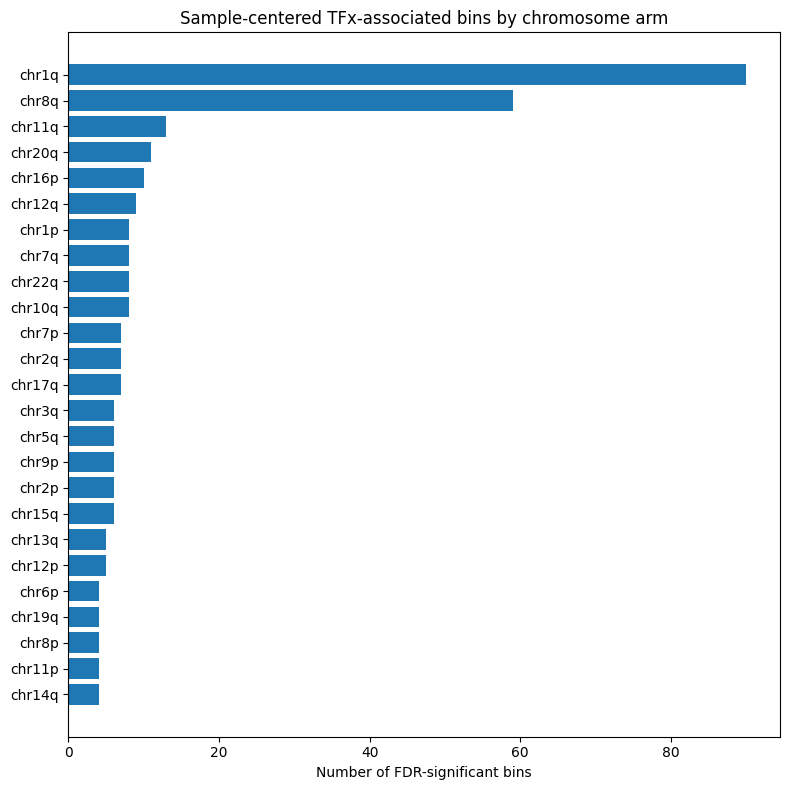

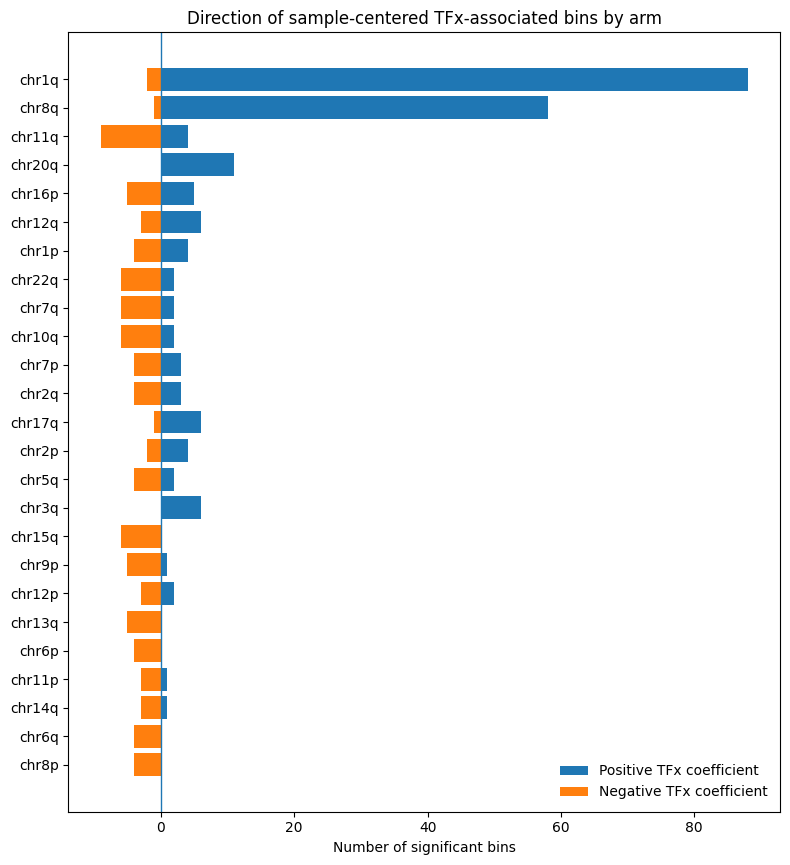

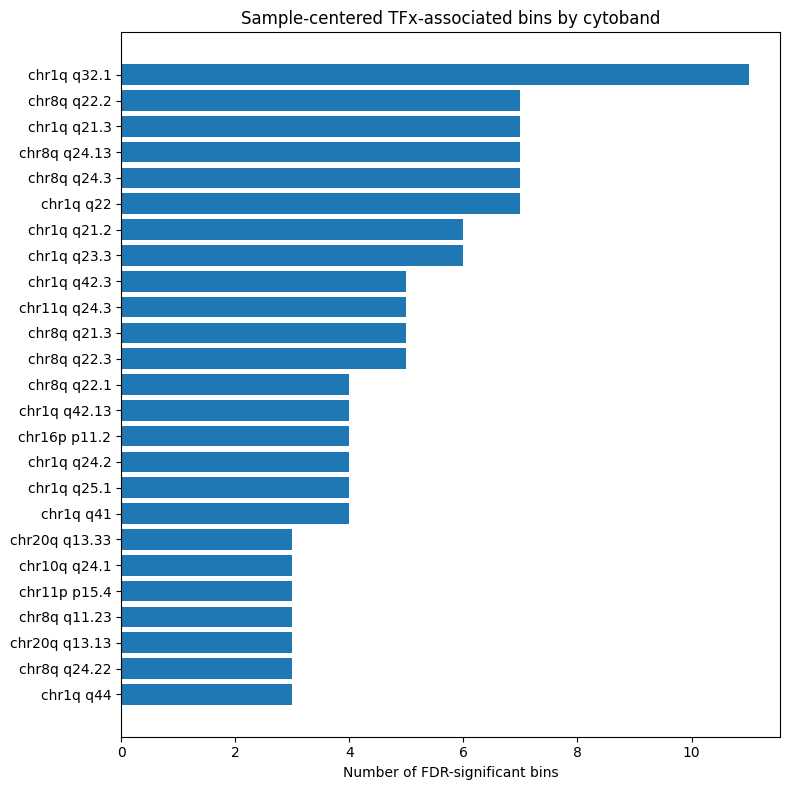

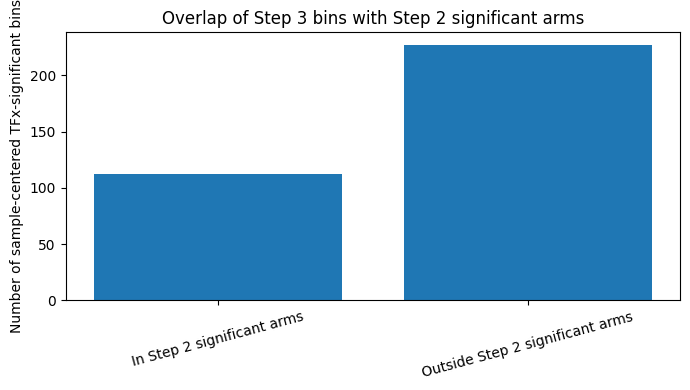

Plots saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step4_biological_interpretation_plots


In [20]:

# ============================================================
# STEP 8: Generate PPT-ready summary plots
# ============================================================

# -------------------------
# Plot 1: top arms by total sample-centered significant TFx bins
# -------------------------

plot_horizontal_bar(
    arm_total,
    label_col="chrom_arm",
    value_col="total_bins",
    path=STEP4_PLOT_DIR / "04_top_chromosome_arms_sample_centered_TFx_bins.png",
    title="Sample-centered TFx-associated bins by chromosome arm",
    xlabel="Number of FDR-significant bins",
    top_n=TOP_N_ARMS_PLOT,
)

# -------------------------
# Plot 2: positive vs negative bins by arm
# -------------------------

direction_arm_for_plot = (
    centered_sig
    .groupby(["chrom_arm", "tfx_direction"], dropna=False)
    .size()
    .reset_index(name="n_bins")
)

plot_direction_stacked_bar(
    direction_arm_for_plot,
    x_col="chrom_arm",
    path=STEP4_PLOT_DIR / "04_positive_negative_sample_centered_TFx_bins_by_arm.png",
    title="Direction of sample-centered TFx-associated bins by arm",
)

# -------------------------
# Plot 3: top cytobands by total bins
# -------------------------

cytoband_total["label"] = cytoband_total["chrom_arm"].astype(str) + " " + cytoband_total["cytoband"].astype(str)

plot_horizontal_bar(
    cytoband_total,
    label_col="label",
    value_col="total_bins",
    path=STEP4_PLOT_DIR / "04_top_cytobands_sample_centered_TFx_bins.png",
    title="Sample-centered TFx-associated bins by cytoband",
    xlabel="Number of FDR-significant bins",
    top_n=TOP_N_CYTOBANDS_PLOT,
)

# -------------------------
# Plot 4: overlap with Step 2 significant arms
# -------------------------

overlap_plot = pd.DataFrame([
    {
        "category": "In Step 2 significant arms",
        "n_bins": int(centered_sig["in_step2_sample_centered_sig_arm"].sum()),
    },
    {
        "category": "Outside Step 2 significant arms",
        "n_bins": int((~centered_sig["in_step2_sample_centered_sig_arm"]).sum()),
    },
])

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(overlap_plot["category"], overlap_plot["n_bins"])
ax.set_ylabel("Number of sample-centered TFx-significant bins")
ax.set_title("Overlap of Step 3 bins with Step 2 significant arms")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(STEP4_PLOT_DIR / "04_overlap_step3_bins_with_step2_significant_arms.png", dpi=300)
plt.show()

print("Plots saved to:", STEP4_PLOT_DIR)


Loading regional matrix for primary-bin heatmaps...
Top heatmap bins: 100


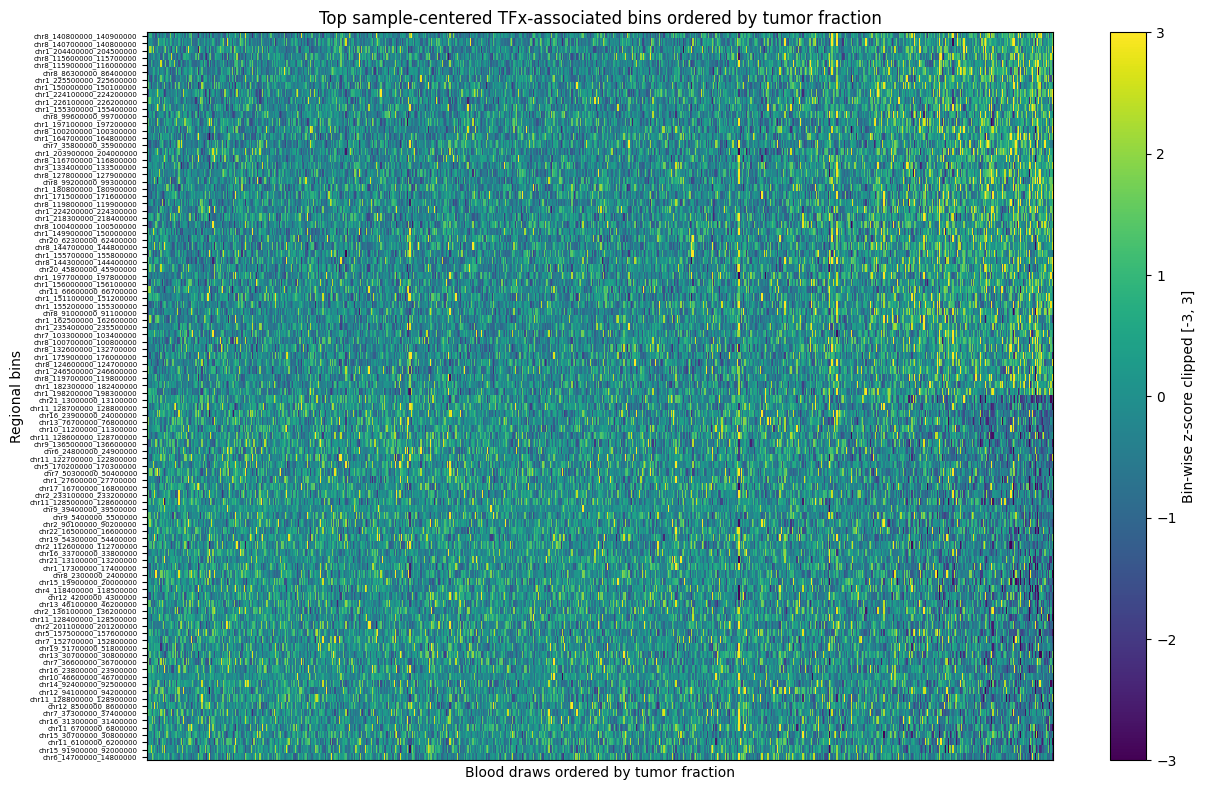

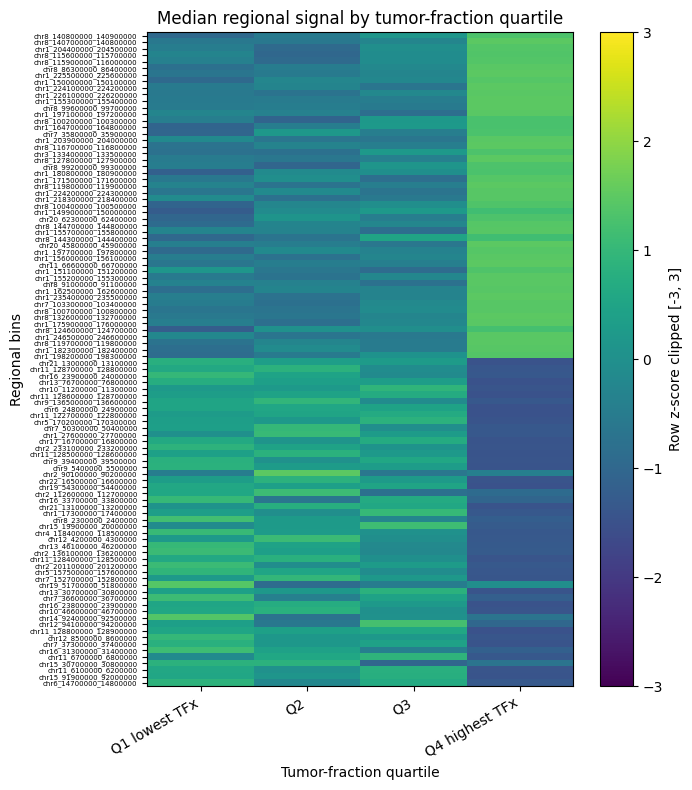

In [21]:

# ============================================================
# STEP 9: Create cleaner tumor-fraction quartile heatmaps
# ============================================================

# This step reloads the regional matrix and computes sample-centered values
# only for the primary significant bins.

print("Loading regional matrix for primary-bin heatmaps...")

regional = pd.read_csv(REGIONAL_FILE, low_memory=False)
sample_col = regional.columns[0]
regional = regional.rename(columns={sample_col: "Barcode"})
regional["Barcode"] = regional["Barcode"].apply(clean_barcode)

primary_bins = centered_sig["bin"].dropna().unique().tolist()

regional_indexed = regional.set_index("Barcode")

missing_bins = [b for b in primary_bins if b not in regional_indexed.columns]
missing_samples = [b for b in analysis_ready["Barcode"] if b not in regional_indexed.index]

if len(missing_bins) > 0:
    raise ValueError(f"Missing primary bins from regional matrix. Example: {missing_bins[:5]}")

if len(missing_samples) > 0:
    raise ValueError(f"Missing analysis-ready samples from regional matrix. Example: {missing_samples[:5]}")

X_primary_raw = regional_indexed.loc[analysis_ready["Barcode"], primary_bins].copy()
X_primary_raw = X_primary_raw.apply(pd.to_numeric, errors="coerce").astype(np.float32)
X_primary_raw.index = analysis_ready.index

# To sample-center correctly, we need each sample's median across all bins.
# If sample medians were saved from Step 3, use them; otherwise compute from all annotated bins.
sample_median_file = STEP3_TABLE_DIR / "03_sample_median_used_for_centering.csv"

if sample_median_file.exists():
    sample_medians = pd.read_csv(sample_median_file)
    sample_medians["Barcode"] = sample_medians["Barcode"].apply(clean_barcode)
    sample_median_map = sample_medians.set_index("Barcode")["sample_median_raw_regional_short_long_ratio"]
    sample_median_vector = analysis_ready["Barcode"].map(sample_median_map).values
else:
    print("Step 3 sample median file not found. Computing sample medians across all bins.")
    all_bins = bin_annot["bin"].tolist()
    X_all = regional_indexed.loc[analysis_ready["Barcode"], all_bins].copy()
    X_all = X_all.apply(pd.to_numeric, errors="coerce").astype(np.float32)
    sample_median_vector = X_all.median(axis=1, skipna=True).values
    del X_all

X_primary_centered = X_primary_raw.sub(sample_median_vector, axis=0).astype(np.float32)

# Add tumor-fraction quartiles.
plot_anno = analysis_ready.copy()
plot_anno["TFx_quartile"] = pd.qcut(
    plot_anno[TFX_COL],
    q=4,
    labels=["Q1 lowest TFx", "Q2", "Q3", "Q4 highest TFx"],
    duplicates="drop",
)

# Select top positive and negative bins by q-value.
top_pos_bins = (
    centered_sig_pos
    .sort_values("q_tumor_fraction_percent")
    .head(TOP_N_POSITIVE_BINS_FOR_HEATMAP)["bin"]
    .tolist()
)

top_neg_bins = (
    centered_sig_neg
    .sort_values("q_tumor_fraction_percent")
    .head(TOP_N_NEGATIVE_BINS_FOR_HEATMAP)["bin"]
    .tolist()
)

top_heatmap_bins = top_pos_bins + top_neg_bins
top_heatmap_bins = [b for b in top_heatmap_bins if b in X_primary_centered.columns]

print("Top heatmap bins:", len(top_heatmap_bins))

# -------------------------
# Sample-level heatmap ordered by tumor fraction
# -------------------------

sample_order = (
    plot_anno
    .sort_values([TFX_COL, "Patient_Identifier"])
    .index
    .tolist()
)

mat = X_primary_centered.loc[sample_order, top_heatmap_bins].T.copy()

# Row-wise z-score.
mat_z = mat.sub(mat.mean(axis=1), axis=0)
mat_z = mat_z.div(mat.std(axis=1).replace(0, np.nan), axis=0)
mat_z = mat_z.clip(-3, 3).fillna(0)

fig, ax = plt.subplots(figsize=(13, max(5, 0.08 * mat_z.shape[0])))
im = ax.imshow(mat_z.values, aspect="auto", interpolation="nearest", vmin=-3, vmax=3)
ax.set_title("Top sample-centered TFx-associated bins ordered by tumor fraction")
ax.set_xlabel("Blood draws ordered by tumor fraction")
ax.set_ylabel("Regional bins")
ax.set_xticks([])
ax.set_yticks(np.arange(mat_z.shape[0]))
ax.set_yticklabels(top_heatmap_bins, fontsize=5)
fig.colorbar(im, ax=ax, label="Bin-wise z-score clipped [-3, 3]")
fig.tight_layout()
fig.savefig(STEP4_PLOT_DIR / "04_heatmap_top_sample_centered_TFx_bins_ordered_by_TFx.png", dpi=300)
plt.show()

# -------------------------
# Tumor-fraction quartile median heatmap
# -------------------------

quartile_medians = []

for q in plot_anno["TFx_quartile"].dropna().unique():
    idx = plot_anno.index[plot_anno["TFx_quartile"].eq(q)]
    med = X_primary_centered.loc[idx, top_heatmap_bins].median(axis=0, skipna=True)
    quartile_medians.append(pd.DataFrame({
        "bin": top_heatmap_bins,
        "TFx_quartile": str(q),
        "median_sample_centered_ratio": med.reindex(top_heatmap_bins).values,
    }))

quartile_medians = pd.concat(quartile_medians, axis=0, ignore_index=True)

quartile_wide = quartile_medians.pivot(
    index="bin",
    columns="TFx_quartile",
    values="median_sample_centered_ratio",
)

quartile_wide = quartile_wide.reindex(top_heatmap_bins)

# Row-wise z-score for display.
quartile_z = quartile_wide.sub(quartile_wide.mean(axis=1), axis=0)
quartile_z = quartile_z.div(quartile_wide.std(axis=1).replace(0, np.nan), axis=0)
quartile_z = quartile_z.clip(-3, 3).fillna(0)

quartile_medians.to_csv(
    STEP4_TABLE_DIR / "04_top_sample_centered_TFx_bins_median_by_TFx_quartile_long.csv",
    index=False,
)

quartile_wide.to_csv(
    STEP4_TABLE_DIR / "04_top_sample_centered_TFx_bins_median_by_TFx_quartile_wide.csv",
)

fig, ax = plt.subplots(figsize=(7, max(5, 0.08 * quartile_z.shape[0])))
im = ax.imshow(quartile_z.values, aspect="auto", interpolation="nearest", vmin=-3, vmax=3)
ax.set_title("Median regional signal by tumor-fraction quartile")
ax.set_xlabel("Tumor-fraction quartile")
ax.set_ylabel("Regional bins")
ax.set_xticks(np.arange(quartile_z.shape[1]))
ax.set_xticklabels(quartile_z.columns, rotation=30, ha="right")
ax.set_yticks(np.arange(quartile_z.shape[0]))
ax.set_yticklabels(quartile_z.index, fontsize=5)
fig.colorbar(im, ax=ax, label="Row z-score clipped [-3, 3]")
fig.tight_layout()
fig.savefig(STEP4_PLOT_DIR / "04_heatmap_top_sample_centered_TFx_bins_by_TFx_quartile.png", dpi=300)
plt.show()

# Clean memory.
del regional
del regional_indexed
del X_primary_raw


In [22]:

# ============================================================
# STEP 10: Nearby-gene annotation
# ============================================================

if GTF_FILE is None:
    print("GTF_FILE is None. Skipping nearby-gene annotation.")
    print("To run this step, set GTF_FILE in Step 1 to a GENCODE/GTF annotation file.")
    gene_annotated_bins = pd.DataFrame()

elif not Path(GTF_FILE).exists():
    print("GTF file does not exist:", GTF_FILE)
    print("Skipping nearby-gene annotation.")
    gene_annotated_bins = pd.DataFrame()

else:
    print("Loading genes from:", GTF_FILE)
    genes = load_gene_gtf(GTF_FILE)
    print("Loaded gene intervals:", genes.shape)
    display(genes.head())

    gene_annotated_bins = annotate_nearest_gene(
        bins_df=centered_sig,
        genes_df=genes,
        window_bp=NEAREST_GENE_WINDOW_BP,
    )

    gene_annotated_bins.to_csv(
        STEP4_TABLE_DIR / "04_primary_sample_centered_TFx_bins_nearest_gene_annotation.csv",
        index=False,
    )

    print("Annotated primary bins:")
    display(gene_annotated_bins.head(20))


Loading genes from: /ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/gencode.v47.annotation.gtf
Loaded gene intervals: (78724, 7)


,chrom,start,end,strand,gene_id,gene_name,gene_type
0,chr1,11120,24894,+,ENSG00000290825.2,DDX11L16,lncRNA
124,chr1,12009,13670,+,ENSG00000223972.6,DDX11L1,transcribed_unprocessed_pseudogene
132,chr1,14355,30744,-,ENSG00000310526.1,WASH7P,lncRNA
2403,chr1,14695,24886,-,ENSG00000227232.6,WASH7P,transcribed_unprocessed_pseudogene
2415,chr1,17368,17436,-,ENSG00000278267.1,MIR6859-1,miRNA


Annotated primary bins:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction,tfx_direction,in_step2_sample_centered_sig_arm,overlapping_gene_names,nearest_gene_name,nearest_gene_distance_bp,nearest_gene_type
0,chr8_140800000_140900000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre,positive,True,ENSG00000279786;PTK2,PTK2,0,protein_coding
1,chr21_13000000_13100000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,lower_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre,negative,False,ANKRD30BP2;ENSG00000229306;ENSG00000290568;ENS...,ANKRD30BP2,0,transcribed_unprocessed_pseudogene
2,chr8_140700000_140800000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre,positive,True,MIR151A;PTK2,PTK2,0,protein_coding
3,chr11_128700000_128800000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,lower_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre,negative,True,FLI1,FLI1,0,protein_coding
4,chr1_204400000_204500000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre,positive,False,ENSG00000288934;PIK3C2B;PPP1R15B;PPP1R15B-AS1,PIK3C2B,0,protein_coding
5,chr8_115600000_115700000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre,positive,True,TRPS1,TRPS1,0,protein_coding
6,chr16_23900000_24000000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,lower_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre,negative,False,ENSG00000279276;PRKCB,PRKCB,0,protein_coding
7,chr8_115900000_116000000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre,positive,True,ENSG00000299498;LINC00536,ENSG00000299498,0,lncRNA
8,chr8_86300000_86400000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre,positive,True,SLC7A13;WWP1;WWP1-AS1,WWP1,0,protein_coding
9,chr13_76700000_76800000,sample_centered,cluster_ols,750,260,74,491,185,ok,NaN,...,0,lower_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre,negative,False,ENSG00000285572;ENSG00000287018;ENSG00000303060,ENSG00000285572,0,lncRNA


In [24]:

# ============================================================
# STEP 11: Create final Step 4 summary and scientific notes
# ============================================================

# Build a compact final summary.
final_summary_rows = [
    {
        "metric": "primary_result_set",
        "value": "sample_centered_FDR_significant_TFx_bins",
    },
    {
        "metric": "n_primary_bins",
        "value": centered_sig.shape[0],
    },
    {
        "metric": "n_positive_TFx_coefficient_bins",
        "value": centered_sig_pos.shape[0],
    },
    {
        "metric": "n_negative_TFx_coefficient_bins",
        "value": centered_sig_neg.shape[0],
    },
    {
        "metric": "n_bins_in_step2_sample_centered_significant_arms",
        "value": int(centered_sig["in_step2_sample_centered_sig_arm"].sum()),
    },
    {
        "metric": "percent_bins_in_step2_sample_centered_significant_arms",
        "value": 100 * centered_sig["in_step2_sample_centered_sig_arm"].mean(),
    },
    {
        "metric": "top_arm_by_bin_count",
        "value": arm_total.iloc[0]["chrom_arm"] if arm_total.shape[0] > 0 else "",
    },
    {
        "metric": "top_arm_bin_count",
        "value": int(arm_total.iloc[0]["total_bins"]) if arm_total.shape[0] > 0 else 0,
    },
]

final_summary = pd.DataFrame(final_summary_rows)
final_summary.to_csv(
    STEP4_TABLE_DIR / "04_step4_final_summary.tsv",
    sep="\t",
    index=False,
)

display(final_summary)

notes = f"""
AURORA regional fragmentation Step 4 notes

Purpose:
Step 4 includes biological interpretation of the primary sample-centered tumor-fraction-associated regional bins. 
This includes chromosome-arm and cytoband summaries, comparison with Step 2 significant chromosome arms, BED file generation, and nearby/overlapping gene annotation using the GENCODE v47 GTF file.

Primary result set:
FDR-significant tumor-fraction-associated bins from the sample-centered regional matrix.

Why sample-centered bins are prioritized:
Raw regional bins capture both global sample-wide fragmentation shifts and local regional effects.
Sample-centering subtracts each sample's genome-wide median regional short/long ratio, highlighting
regional redistribution beyond the sample-wide shift.

Primary result:
Number of sample-centered TFx-associated bins: {centered_sig.shape[0]}
Positive TFx coefficient bins: {centered_sig_pos.shape[0]}
Negative TFx coefficient bins: {centered_sig_neg.shape[0]}

Step 2 connection:
Number of primary bins falling within Step 2 sample-centered significant arms:
{int(centered_sig["in_step2_sample_centered_sig_arm"].sum())}

Percent within Step 2 significant arms:
{100 * centered_sig["in_step2_sample_centered_sig_arm"].mean():.2f}%

Interpretation:
Positive TFx coefficient:
As tumor fraction increases, that bin becomes relatively higher in short/long ratio compared with
the sample's genome-wide median regional ratio.

Negative TFx coefficient:
As tumor fraction increases, that bin becomes relatively lower in short/long ratio compared with
the sample's genome-wide median regional ratio.

Recommended conclusion:
Tumor fraction is associated with broad raw regional fragmentation shifts and with a smaller set of
sample-centered regional fragmentation changes. The sample-centered results suggest tumor-burden-associated
regional redistribution of cfDNA fragmentation. Treatment context did not show a robust FDR-significant
regional fragmentation association in Step 3.

Main Step 4 outputs:
Tables:
{STEP4_TABLE_DIR}

Plots:
{STEP4_PLOT_DIR}

BED files:
{STEP4_BED_DIR}

Additional downstream analysis:
The BED files generated in Step 4 can be used later for regulatory or genomic enrichment analysis. Gene annotation using the GENCODE v47 GTF file is included within Step 4.
"""

notes_path = STEP4_TABLE_DIR / "04_step4_scientific_notes.txt"

with open(notes_path, "w") as fh:
    fh.write(notes.strip() + "\n")

print(notes)
print("Saved notes:", notes_path)
print("Step 4 notebook completed:", time.ctime())


,metric,value
0,primary_result_set,sample_centered_FDR_significant_TFx_bins
1,n_primary_bins,339
2,n_positive_TFx_coefficient_bins,220
3,n_negative_TFx_coefficient_bins,119
4,n_bins_in_step2_sample_centered_significant_arms,112
5,percent_bins_in_step2_sample_centered_signific...,33.038348
6,top_arm_by_bin_count,chr1q
7,top_arm_bin_count,90



AURORA regional fragmentation Step 4 notes

Purpose:
Step 4 includes biological interpretation of the primary sample-centered tumor-fraction-associated regional bins. 
This includes chromosome-arm and cytoband summaries, comparison with Step 2 significant chromosome arms, BED file generation, and nearby/overlapping gene annotation using the GENCODE v47 GTF file.

Primary result set:
FDR-significant tumor-fraction-associated bins from the sample-centered regional matrix.

Why sample-centered bins are prioritized:
Raw regional bins capture both global sample-wide fragmentation shifts and local regional effects.
Sample-centering subtracts each sample's genome-wide median regional short/long ratio, highlighting
regional redistribution beyond the sample-wide shift.

Primary result:
Number of sample-centered TFx-associated bins: 339
Positive TFx coefficient bins: 220
Negative TFx coefficient bins: 119

Step 2 connection:
Number of primary bins falling within Step 2 sample-centered significa